In [1]:
import os
import zipfile
import cv2
import random
import keras

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

In [2]:
data_path = Path("/kaggle/input/datasets/ihmaditaha/tumors/Data")

image_count = len(list(data_path.glob('*/*.jpg')))
print(image_count)

7023


In [3]:
batch_size = 32
img_height = 224
img_width = 224
AUTOTUNE = tf.data.AUTOTUNE
print("Num GPUs Available:", len(tf.config.list_physical_devices("GPU")))

Num GPUs Available: 2


In [4]:
list_ds = tf.data.Dataset.list_files(str(data_path/'*/*'), shuffle=False)
list_ds = list_ds.shuffle(image_count, reshuffle_each_iteration=False)

I0000 00:00:1793199587.560444    3340 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793199587.562666    3340 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [5]:
class_names = np.array(sorted([item.name for item in data_path.glob('*')]))
print(class_names)

['glioma' 'meningioma' 'notumor' 'pituitary']


In [6]:
test_size = int(image_count * 0.1)
temp_ds = list_ds.skip(test_size)
test_ds = list_ds.take(test_size)
train_ds = temp_ds.skip(test_size)
val_ds = temp_ds.take(test_size)

In [7]:
print(tf.data.experimental.cardinality(train_ds).numpy())
print(tf.data.experimental.cardinality(val_ds).numpy())
print(tf.data.experimental.cardinality(test_ds).numpy())

5619
702
702


In [8]:
def get_label(file_path):
  parts = tf.strings.split(file_path, os.path.sep)
  one_hot = parts[-2] == class_names
  return one_hot

def decode_img(img):
  img = tf.io.decode_jpeg(img, channels=3)
  return tf.image.resize(img, [img_height, img_width])

def process_path(file_path):
  label = get_label(file_path)
  img = tf.io.read_file(file_path)
  img = decode_img(img)
  return img, label

In [9]:
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(process_path, num_parallel_calls=AUTOTUNE)

In [10]:
for image, label in train_ds.take(1):
  print("Image shape: ", image.numpy().shape)
  print("Label: ", label.numpy())

Image shape:  (224, 224, 3)
Label:  [ True False False False]


In [11]:
def prepare(ds, shuffle=False):
    
  ds = ds.cache()
  if shuffle:
    ds = ds.shuffle(1000)
  ds = ds.batch(batch_size)
  ds = ds.prefetch(buffer_size=AUTOTUNE)

  return ds

train_ds = prepare(train_ds, shuffle=True)
val_ds = prepare(val_ds)
test_ds = prepare(test_ds)

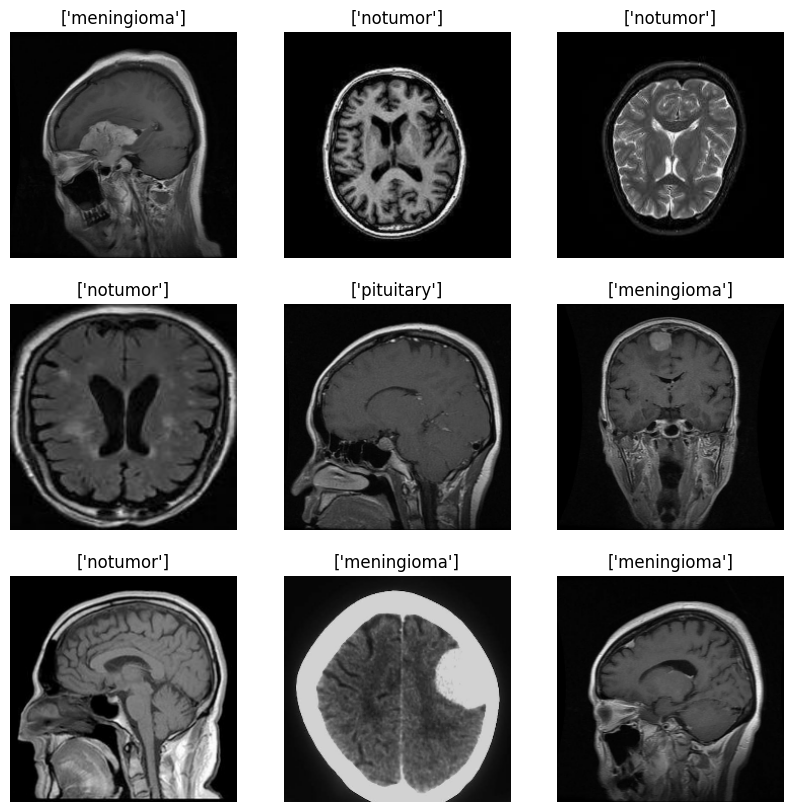

In [12]:
image_batch, label_batch = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].numpy().astype("uint8"))
  label = label_batch[i]
  plt.title(class_names[label])
  plt.axis("off")

In [13]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

In [14]:
data_augmentation = tf.keras.Sequential([
  keras.layers.RandomFlip("horizontal_and_vertical"),
  keras.layers.RandomRotation(0.2),
],name="Data_augmentation")

In [15]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
print(np.min(first_image), np.max(first_image))

0.0 0.9222677


In [16]:
num_classes = 4

model = tf.keras.Sequential([
  tf.keras.layers.Input(shape=(224,224,3)),
  data_augmentation,
  normalization_layer,
  tf.keras.layers.Conv2D(32, (3,3), activation='relu',name="conv1"),
  tf.keras.layers.MaxPooling2D((2,2),name="maxpool1"),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu',name="conv2"),
  tf.keras.layers.MaxPooling2D((2,2),name="maxpool2"),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu',name="conv3"),
  tf.keras.layers.MaxPooling2D((2,2),name="maxpool3"),
  tf.keras.layers.Conv2D(256, (3,3), activation='relu', name="conv4"),
  tf.keras.layers.MaxPooling2D((2,2), name="maxpool4"),
  tf.keras.layers.Flatten(name="flatten1"),
  tf.keras.layers.Dense(128, activation='relu',name="FC1"),
  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Dense(num_classes,activation='softmax',name="FC2")
],name="cnn_model")
model.summary()

Model: "cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool3 (MaxPooling2D)         │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool4 (MaxPooling2D)         │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten1 (Flatten)              │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC1 (Dense)                     │ (None, 128)            │     4,718,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC2 (Dense)                     │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,107,652 (19.48 MB)

 Trainable params: 5,107,652 (19.48 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
  optimizer=keras.optimizers.Adam(learning_rate=0.0001),
  loss='categorical_crossentropy',
  metrics=['accuracy'])

In [18]:
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=30,
  callbacks=[
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    keras.callbacks.EarlyStopping(patience=4,verbose=1),
    keras.callbacks.ModelCheckpoint(filepath='best_model.keras',save_best_only=True),
    keras.callbacks.BackupAndRestore("backup/", save_freq="epoch")
    ]
)


Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 31s 143ms/step - accuracy: 0.6804 - loss: 0.8346 - val_accuracy: 0.7236 - val_loss: 0.7123 - learning_rate: 1.0000e-04
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.7179 - loss: 0.7333 - val_accuracy: 0.7436 - val_loss: 0.6589 - learning_rate: 1.0000e-04
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.7386 - loss: 0.6743 - val_accuracy: 0.7721 - val_loss: 0.5844 - learning_rate: 1.0000e-04
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.7592 - loss: 0.6378 - val_accuracy: 0.8077 - val_loss: 0.5473 - learning_rate: 1.0000e-04
Epoch 6/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 60ms/step - accuracy: 0.7660 - loss: 0.6050 - val_accuracy: 0.7464 - val_loss: 0.6272 - learning_rate: 1.0000e-04
Epoch 7/30
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7756 - loss: 0.5825
Epoch 7: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 60ms/step - a

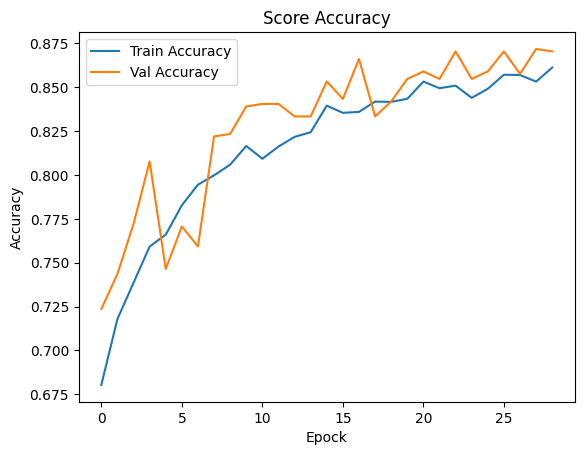

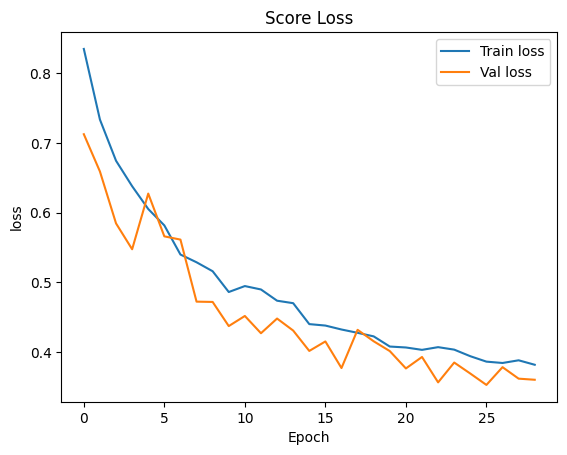

In [19]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Score Accuracy')
plt.xlabel('Epock')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


plt.figure()
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.title('Score Loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [20]:
test_loss, test_accuracy = model.evaluate(test_ds,
    batch_size=32
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - accuracy: 0.8476 - loss: 0.3958
Test Loss: 0.3958
Test Accuracy: 84.76%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


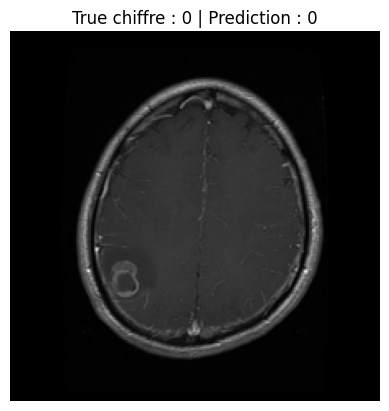

In [30]:
for images, labels in test_ds.take(1):
    image = images[7] /255.0
    label = np.argmax(labels[7])

input_image = tf.expand_dims(image, axis=0)

probabilities = model.predict(input_image)
predicted_label = np.argmax(probabilities)

plt.imshow(image)
plt.title(f"True chiffre : {label} | Prediction : {predicted_label}")
plt.axis("off")
plt.show()

In [34]:
y_true = np.concatenate([labels for _, labels in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)
y_pred = model.predict(test_ds , batch_size=32)
y_pred = np.argmax(y_pred , axis=1)
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
))

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
              precision    recall  f1-score   support

      glioma       0.81      0.85      0.83       156
  meningioma       0.84      0.64      0.73       191
     notumor       0.91      0.95      0.93       187
   pituitary       0.81      0.97      0.89       168

    accuracy                           0.85       702
   macro avg       0.85      0.85      0.84       702
weighted avg       0.85      0.85      0.84       702



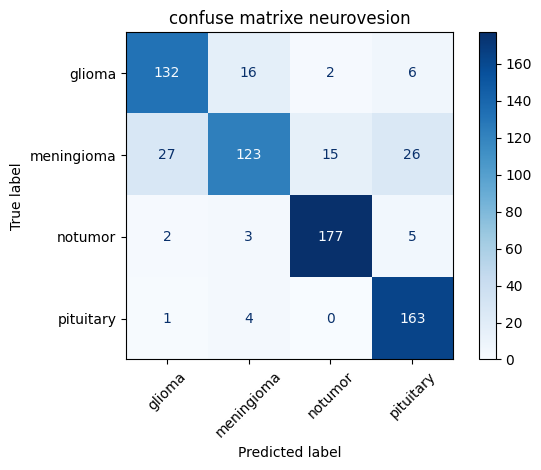

In [35]:
cm = confusion_matrix(y_true , y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,display_labels=class_names
)

display.plot(cmap="Blues" , xticks_rotation=45)
plt.title("confuse matrixe neurovesion")
plt.tight_layout()
plt.show()